---
<a name='title'></a>
# **<font color="Navy"> Física del clima </font>**
## **<font color="RoyalBlue"> Termodinámica </font>**
### **<font color="DodgerBlue"> Notebook 2: Termodinámica del aire atmosférico </font>**
### Escuela Nacional de Ciencias de la Tierra
#### **<font color="Forestgreen"> Semestre 2027-1  </font>**

---

### **<font color="ForestGreen"> Introducción </font>**

La termodinámica es la rama de la física que describe cómo un sistema intercambia **energía** con su entorno y cómo ese intercambio se refleja en sus propiedades macroscópicas. No le interesa el detalle de cada molécula, sino un puñado de **variables de estado** que resumen la condición del sistema completo: la presión $p$, el volumen $V$, la temperatura $T$ y la masa.

Para un gas ideal estas variables no son independientes: están amarradas por una **ecuación de estado**,

\begin{align}
pV = nRT,
\end{align}

de modo que fijar dos de ellas determina la tercera. Esto tiene una consecuencia geométrica útil: el estado de la parcela es un **punto** en un plano, y un proceso termodinámico es una **curva** que une dos puntos. Podemos dibujar ese plano como $p$–$V$, como $p$–$T$ o como $V$–$T$; los tres describen lo mismo desde ángulos distintos.

La distinción central del curso es entre dos tipos de cantidades:

- Las **funciones de estado** (como la energía interna $U$, o la entropía $S$) dependen únicamente de dónde está el sistema, no de cómo llegó ahí.
- Las **funciones de camino** (como el calor $Q$ y el trabajo $W$) dependen de la trayectoria completa que siguió el sistema.

Esta diferencia no es un tecnicismo: es la razón por la que en la atmósfera importa *cómo* asciende una parcela de aire, y no sólo dónde empieza y dónde termina.

Trabajaremos con cuatro procesos reversibles fundamentales, cada uno definido por mantener fija una cantidad:

| Proceso | Se mantiene constante | Relación |
|---|---|---|
| Isotérmico | $T$ | $pV=\text{cte}$ |
| Isobárico | $p$ | $V/T=\text{cte}$ |
| Isocórico | $V$ | $p/T=\text{cte}$ |
| Adiabático | $Q=0$ (no el calor total, sino el intercambio) | $pV^\gamma=\text{cte}$ |

El proceso adiabático es el que más nos va a interesar. Una parcela de aire que asciende en la atmósfera se expande (porque la presión ambiente disminuye) y lo hace tan rápido, comparado con lo que tarda en intercambiar calor con el aire que la rodea, que podemos tratar el intercambio como nulo. La mayor parte de la meteorología de parcelas descansa sobre esa aproximación.

### **<font color="ForestGreen"> Ruta del notebook </font>**

1. **Procesos y la primera ley.** Llevamos un gas ideal de un estado inicial a uno final por tres caminos distintos y verificamos que $\Delta U$ es el mismo en los tres, pero el trabajo no.
2. **La ecuación de Clausius-Clapeyron.** Introducimos el vapor de agua y deducimos cómo la presión de saturación depende de la temperatura.
3. **Adiabáticas secas y húmedas.** Construimos las trayectorias que sigue una parcela al ascender, con y sin condensación.

A lo largo del notebook hay ejercicios marcados en <font color="DodgerBlue">**azul**</font> que tendrás que resolver tú.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
def lineplot_setup(xmin,xmax,xlab,ylab,ymin=None,ymax=None,title=None):
    # especificar limites minimos y maximos del grafico
    plt.xlim([xmin,xmax])
    plt.ylim([ymin,ymax])
    # cuadrilla interna del grafico
    plt.grid(linestyle='--',alpha=0.66)
    plt.minorticks_on()
    # hacer las etiquetas de ambos ejes mas grandes
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.xlabel(xlab,fontsize=14)
    plt.ylabel(ylab,fontsize=14)
    plt.title(title,fontsize=15)

---
### **<font color="ForestGreen"> Procesos termodinámicos y la primera ley </font>**

Antes de entrar a la termodinámica del agua, conviene recordar cómo se contabilizan el calor $Q$, el trabajo $W$ y el cambio de energía interna $\Delta U$ cuando una parcela de gas cambia de estado. Todo se apoya en la **primera ley de la termodinámica**,

\begin{align}
\Delta U = Q - W, \qquad W = \int_i^f p\,dV,
\end{align}

y en el hecho de que $U$ es una **función de estado**: su cambio depende sólo de los estados inicial y final, no del camino. El calor y el trabajo, en cambio, **sí** dependen del camino. Para un gas ideal $U=U(T)$, de modo que $\Delta U = C_V\,\Delta T$ y, en particular, $\Delta U = 0$ en cualquier proceso isotérmico.

Vamos a trabajar el siguiente problema clásico (ejemplo 4.3 del texto), que nos llevará por los cuatro procesos reversibles fundamentales:

> **Problema.** Calcular $Q$, $W$ y $\Delta U$ para llevar un gas ideal del estado $i=(p_i,V_i)$ al estado $f=(p_f,V_f)$ por tres caminos distintos (ver Figura 4.8), con $p_f>p_i$ (compresión):
>
> **(a)** compresión isotérmica reversible $i\to f$;
>
> **(b)** compresión adiabática reversible $i\to m=(p_f,V_m)$ seguida de compresión isobárica reversible $m\to f$;
>
> **(c)** aumento isocórico reversible de temperatura $i\to m'=(p_f,V_i)$ seguido de una disminución isobárica reversible de temperatura $m'\to f$.
>
> Expresa todo en términos de $p_i$, $p_f$ y $T$, la temperatura de la isoterma en (a).

Los tres caminos comparten los mismos extremos $i$ y $f$. Como $i$ y $f$ están sobre **la misma isoterma** (el proceso (a) es isotérmico), la temperatura inicial y final coinciden en los tres casos y por lo tanto

\begin{align}
\boxed{\Delta U = 0 \quad\text{en (a), (b) y (c)}} \;\Rightarrow\; Q=W \text{ para el proceso completo.}
\end{align}

Lo que cambia entre caminos es **cómo** se reparten $Q$ y $W$ a lo largo del recorrido. Dibujemos primero el diagrama $p$–$V$.

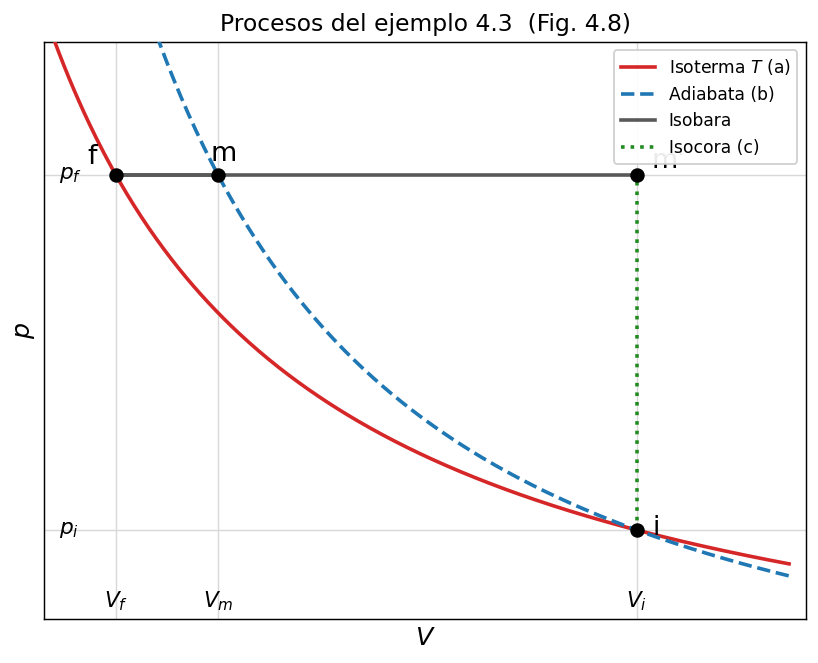

In [2]:
# --- Esquema de los procesos del ejemplo 4.3 (Figura 4.8) ---
# Valores ILUSTRATIVOS (no son el resultado del problema, sólo sirven
# para dibujar las curvas con la geometría correcta).
gamma = 1.4                     # cp/cv para aire seco (gas diatómico ideal)
Vi, pi = 1.0, 1.0               # estado inicial i
pf      = 2.6                   # presión final (pf > pi -> compresión)

# f está sobre la MISMA isoterma que i:  p_i V_i = p_f V_f
C_iso = pi*Vi
Vf = C_iso/pf
# La adiabática desde i alcanza la presión pf en el volumen Vm:
#   p_i V_i^gamma = p_f V_m^gamma
Vm = Vi*(pi/pf)**(1/gamma)
C_ad = pi*Vi**gamma

fig, ax = plt.subplots(figsize=(6.4, 5.2), dpi=130)
V = np.linspace(0.30, 1.18, 300)

# Isoterma (proceso a) y adiabática (primer tramo de b)
ax.plot(V, C_iso/V,        c='tab:red',  lw=2,           label='Isoterma $T$ (a)', zorder=3)
ax.plot(V, C_ad/V**gamma,  c='tab:blue', lw=2, ls='--',  label='Adiabata (b)',     zorder=3)
# Isobara a p = pf (tramos m->f y m'->f)
ax.plot([Vm, Vf], [pf, pf], c='0.35', lw=2,              label='Isobara',          zorder=2)
ax.plot([Vi, Vf], [pf, pf], c='0.35', lw=2,                                        zorder=1)
# Isocora a V = Vi (primer tramo de c)
ax.plot([Vi, Vi], [pi, pf], c='forestgreen', lw=2, ls=':', label='Isocora (c)',    zorder=2)

# Estados
for nm,(x,y),off in [('i',(Vi,pi),(9,-3)), ('f',(Vf,pf),(-16,6)),
                     ('m',(Vm,pf),(-4,8)), ("m'",(Vi,pf),(8,4))]:
    ax.plot(x, y, 'ko', ms=7, zorder=6)
    ax.annotate(nm, (x,y), textcoords='offset points', xytext=off, fontsize=15)

# Guías p_i, p_f, V_i, V_f, V_m
for Vx,lab in [(Vi,'$V_i$'),(Vf,'$V_f$'),(Vm,'$V_m$')]:
    ax.axvline(Vx, c='0.85', lw=0.8, zorder=0)
    ax.annotate(lab,(Vx,0.02),xycoords=('data','axes fraction'),ha='center',fontsize=12)
for px,lab in [(pi,'$p_i$'),(pf,'$p_f$')]:
    ax.axhline(px, c='0.85', lw=0.8, zorder=0)
    ax.annotate(lab,(0.02,px),xycoords=('axes fraction','data'),va='center',fontsize=12)

ax.set_xlim(0.3,1.2); ax.set_ylim(0.6,3.2)
ax.set_xlabel('$V$', fontsize=14); ax.set_ylabel('$p$', fontsize=14)
ax.set_title('Procesos del ejemplo 4.3  (Fig. 4.8)', fontsize=13)
ax.set_xticks([]); ax.set_yticks([])
ax.legend(loc='upper right', fontsize=9.5, framealpha=0.92)
plt.tight_layout()

> **✏️ Ejercicio rápido.** El esquema usa valores ilustrativos. Nota que los tres caminos salen de $i$ (abajo a la derecha) y terminan en $f$ (arriba a la izquierda), pero recorren regiones muy distintas del plano $p$–$V$. El **trabajo** $W=\int p\,dV$ es el área bajo cada curva: mirando la figura, ¿qué camino te parece que encierra más área, la isoterma (a) o el par adiabata+isobara (b)? Cambia `pf = 2.6` por un valor más grande (por ejemplo `4.0`) y vuelve a correr la celda: ¿cómo se separan las curvas?

#### (a) Compresión isotérmica reversible $i\to f$

Como $T_i=T_f=T$, tenemos $\Delta T=0$ y por lo tanto $\Delta U=0$. De la primera ley, $Q=W$, y usando $p=nR^{*}T/V$:

\begin{align}
Q = W = \int_i^f p\,dV = nR^{*}T \int_i^f \frac{dV}{V}
      = nR^{*}T \ln\frac{V_f}{V_i}
      = nR^{*}T \ln\frac{p_i}{p_f}.
\end{align}

Como es una **compresión** ($p_f>p_i$), el logaritmo es negativo: $W<0$ (se hace trabajo *sobre* el gas) y $Q<0$ (el gas cede calor al entorno).

In [3]:
# Verificación numérica de los tres caminos con valores concretos.
# Elegimos un gas ideal (n moles) y evaluamos W en cada trayectoria.
Rstar = 8.314          # J mol^-1 K^-1
gamma = 1.4
Cv = Rstar/(gamma-1)   # J mol^-1 K^-1  (gas diatómico ideal)
Cp = Cv + Rstar

n  = 1.0               # moles
T  = 300.0             # K, temperatura de la isoterma (a)
pi = 1.0e5             # Pa
pf = 2.5e5             # Pa  (pf > pi -> compresión)

# Volúmenes de los estados a partir de la ley del gas ideal
Vi = n*Rstar*T/pi
Vf = n*Rstar*T/pf                 # f está sobre la isoterma T
Vm = Vi*(pi/pf)**(1/gamma)        # m sobre la adiabática, a p = pf

# (a) isoterma
W_a = n*Rstar*T*np.log(pi/pf)

# (b) adiabata i->m  +  isobara m->f
Tm   = T*(pf/pi)**((gamma-1)/gamma)   # Poisson T-p: compresion calienta
W_b  = -Cv*(Tm - T) + pf*(Vf - Vm)      # W_i->m + W_m->f

# (c) isocora i->m' + isobara m'->f
W_c  = 0.0 + pf*(Vf - Vi)               # W_i->m' = 0

for nombre, W in [('(a) isoterma', W_a),
                  ('(b) adiabata+isobara', W_b),
                  ('(c) isocora+isobara', W_c)]:
    # Como Delta U = 0 en los tres, Q = W
    print(f'{nombre:24s}  W = Q = {W:10.1f} J   (Delta U = 0)')

(a) isoterma              W = Q =    -2285.4 J   (Delta U = 0)
(b) adiabata+isobara      W = Q =    -2612.5 J   (Delta U = 0)
(c) isocora+isobara       W = Q =    -3741.3 J   (Delta U = 0)


> **✏️ Ejercicio rápido.** Corre la celda anterior: los tres caminos dan $\Delta U=0$, pero el trabajo $W$ es distinto en cada uno. ¿Cuál requiere el menor trabajo de compresión (el $W$ menos negativo)? Ahora cambia `pf = 2.5e5` por una **expansión** (`pf = 0.5e5`, con $p_f<p_i$) y observa cómo cambian los signos: ¿cuál camino entrega ahora más trabajo? Este ejercicio ilustra por qué en la atmósfera importa *cómo* asciende o desciende una parcela, no sólo dónde empieza y termina.

---
<a name='ej-1'></a>
### **<font color="DodgerBlue">Ejercicio 1 - Las tres caras de la adiabática</font>**

<font color="DarkBlue"> Para resolver el camino (b) tuviste que usar $pV^\gamma = \text{cte}$ y encontrar el estado intermedio $m$. Pero esa es sólo **una** de las tres formas equivalentes de la relación de Poisson. Las otras dos salen de combinar $pV^\gamma=\text{cte}$ con la ley del gas ideal $pV=nRT$ para eliminar, cada vez, una variable distinta:

\begin{align}
pV^\gamma &= \text{cte} \\
TV^{\gamma-1} &= \text{cte} \\
Tp^{(1-\gamma)/\gamma} &= \text{cte}
\end{align}

<font color="DarkBlue"> Las tres describen **exactamente el mismo proceso físico**, proyectado sobre un plano distinto. Tu trabajo es convencerte de que es así.

<font color="DarkBlue"> **Instrucciones:**

<font color="DarkBlue"> 1. Antes de tocar el teclado, **deriva en papel** las dos relaciones que no te dimos hechas. Cada una es una sola sustitución de $pV=nRT$ en $pV^\gamma=\text{cte}$. Si no puedes hacerlo a mano, no vas a poder interpretar la gráfica.

<font color="DarkBlue"> 2. Elige un estado inicial $(p_i, V_i, T_i)$ y un valor de $\gamma$. Grafica el **mismo** proceso adiabático en tres paneles: $p$–$V$, $V$–$T$ y $p$–$T$. Marca el estado inicial en los tres.

<font color="DarkBlue"> 3. Agrega en cada panel una segunda curva para un gas **monoatómico** ($\gamma = 5/3$) junto a la del aire seco **diatómico** ($\gamma = 7/5$), partiendo del mismo estado inicial.

<font color="DarkBlue"> 4. Responde: ¿en cuál de los tres planos se distingue **mejor** la diferencia entre ambos gases? ¿Por qué crees que en meteorología se prefiere trabajar en el plano $p$–$T$ y no en el $p$–$V$, que es el que aparece en todos los libros de termodinámica general?

<font color="DarkBlue"> **Reto adicional:** sobre el panel $p$–$V$, sobrepón la **isoterma** que pasa por el mismo estado inicial. ¿Cuál de las dos curvas cae más rápido, la adiabática o la isoterma? Explica por qué, apoyándote en que $\gamma > 1$ siempre.

<font color="DarkBlue"> **Salida esperada:** una figura con tres paneles, dos curvas por panel, ejes etiquetados, y un párrafo corto respondiendo las preguntas.


In [4]:
# Estado inicial común a las tres relaciones
pi_, Vi_, Ti_ = 1.0, 1.0, 300.0   # unidades arbitrarias: sólo importa la FORMA de las curvas

# TU CÓDIGO AQUÍ
# Sugerencia de estructura:
#
# fig, axes = plt.subplots(1, 3, figsize=(13, 4), dpi=120)
#
# for gamma, color, etiqueta in [(7/5, 'tab:blue', 'Diatómico'), (5/3, 'tab:red', 'Monoatómico')]:
#     # Panel p-V   : usa  p V^gamma = cte
#     # Panel V-T   : usa  T V^(gamma-1) = cte
#     # Panel p-T   : usa  T p^((1-gamma)/gamma) = cte
#     ...


---
### **<font color="ForestGreen"> La ecuación de Clausius-Clapeyron </font>**

Hasta aquí tratamos el aire como un gas ideal seco. Pero el aire atmosférico contiene vapor de agua, y el agua tiene una particularidad que lo vuelve el ingrediente más interesante del sistema climático: **cambia de fase** a las temperaturas y presiones que se dan de manera cotidiana en la atmósfera.

Cuando un líquido y su vapor coexisten en equilibrio, la presión parcial del vapor tiene un valor bien definido que depende **sólo de la temperatura**: es la **presión de saturación** $e_s(T)$. Si la presión de vapor es menor que $e_s$, el líquido se evapora; si es mayor, el vapor condensa. La ecuación de Clausius-Clapeyron es la que nos dice cómo cambia $e_s$ con $T$:

\begin{align}
\frac{1}{e_s}\frac{d e_s}{dT} = \frac{L}{R_v T^2}
\end{align}

donde $T$ es la temperatura en K, $e_s$ la presión de saturación en Pa, $L$ el calor latente de vaporización ($\approx 2.26\times10^6$ J kg$^{-1}$, es decir energía por unidad de **masa**) y $R_v = 461.5$ J kg$^{-1}$ K$^{-1}$ la constante del gas **para el vapor de agua**, no para el aire seco.

### **<font color="ForestGreen"> ¿De dónde sale? Una máquina de vapor infinitesimal </font>**

Vale la pena ver de dónde sale esta ecuación con un argumento puramente físico, en el espíritu de Feynman: construir una máquina térmica que use el cambio de fase como sustancia de trabajo y exigir que su eficiencia sea la de Carnot.

Imaginemos un pistón que contiene líquido y vapor en equilibrio a temperatura $T$ y presión $e_s$. Lo hacemos recorrer un ciclo cerrado, infinitesimalmente delgado, entre $T$ y $T-\Delta T$:

1. A temperatura $T$, **evaporamos** una masa unitaria de líquido. El sistema absorbe el calor latente $L$ y se expande a presión constante $e_s$, pasando del volumen específico del líquido $V_l$ al del vapor $V_g$.
2. **Enfriamos** infinitesimalmente a $T - \Delta T$, donde la presión de saturación es $e_s - \Delta e$.
3. A esa temperatura menor, **condensamos** el vapor de vuelta a líquido, liberando calor.
4. **Calentamos** de vuelta a $T$, cerrando el ciclo.

El trabajo neto del ciclo es el área encerrada en el plano $p$–$V$. Como el ciclo es infinitesimalmente delgado en presión, esa área es simplemente

\begin{align}
\Delta W = \Delta e \,(V_g - V_l).
\end{align}

Pero este ciclo no es otra cosa que una **máquina de Carnot** operando entre $T$ y $T-\Delta T$, que absorbe el calor $L$ a la temperatura mayor. Su eficiencia debe ser entonces la de Carnot:

\begin{align}
\eta = \frac{\Delta W}{L} = \frac{\Delta T}{T}.
\end{align}

Igualando ambas expresiones para el trabajo y tomando el límite $\Delta T \to 0$:

\begin{align}
\frac{d e_s}{dT} = \frac{L}{T\,(V_g - V_l)}.
\end{align}

Este resultado es **exacto** y vale para cualquier transición de fase. Lo notable es que basta exigir que ninguna máquina supere la eficiencia de Carnot para fijar cómo debe cambiar la presión de saturación con la temperatura.

Para el agua en la atmósfera lo simplificamos con dos observaciones: el volumen específico del vapor es mucho mayor que el del líquido ($V_g \gg V_l$), y el vapor se comporta como gas ideal ($V_g = R_v T/e_s$). Sustituyendo:

\begin{align}
\frac{d e_s}{dT} = \frac{L}{T}\frac{e_s}{R_v T} = \frac{L\, e_s}{R_v T^2},
\end{align}

que es la ecuación con la que vamos a trabajar.


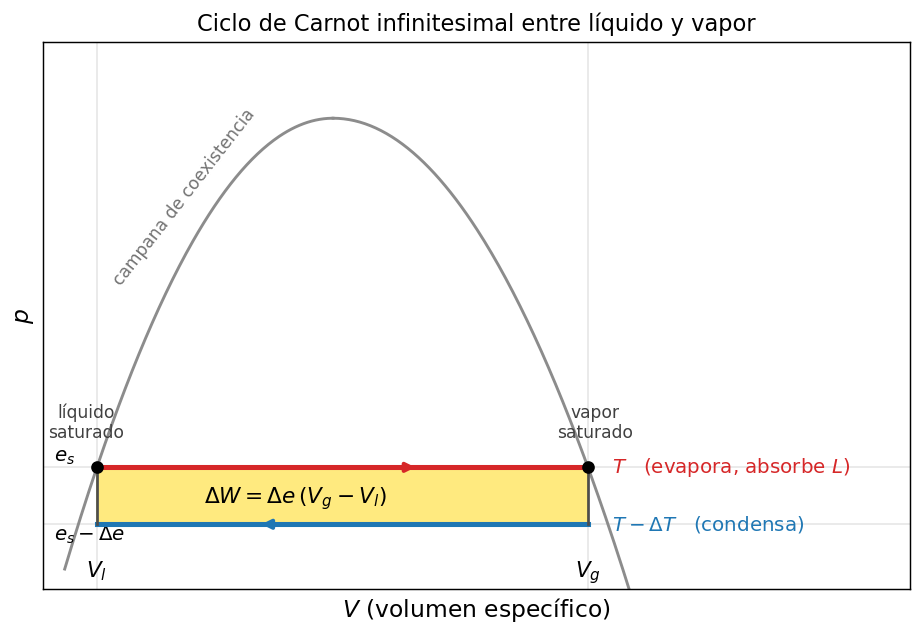

In [5]:
# --- Esquema del ciclo de Carnot infinitesimal en el plano p-V ---
# La región bajo la campana es donde líquido y vapor coexisten: ahí las
# isotermas son HORIZONTALES (la presión no cambia mientras dura el cambio de fase).

fig, ax = plt.subplots(figsize=(7.2, 5), dpi=130)

# Estados del ciclo: líquido saturado (Vl) y vapor saturado (Vg)
Vl, Vg = 0.42, 2.25
es_T   = 1.06          # presión de saturación a T
es_dT  = 0.985         # presión de saturación a T - dT

# Campana de coexistencia, construida para que pase EXACTAMENTE por (Vl, es_T) y (Vg, es_T)
Vc, pc = 1.30, 1.52                      # punto crítico (esquemático)
a_izq = (pc - es_T)/(Vc - Vl)**2
a_der = (pc - es_T)/(Vg - Vc)**2
V_izq = np.linspace(0.30, Vc, 200)
V_der = np.linspace(Vc, 2.62, 200)
ax.plot(V_izq, pc - a_izq*(Vc - V_izq)**2, c='0.55', lw=1.6, zorder=2)
ax.plot(V_der, pc - a_der*(V_der - Vc)**2, c='0.55', lw=1.6, zorder=2)
ax.annotate('campana de coexistencia', (0.47, 1.30), fontsize=9.5, color='0.45', rotation=52)

# Sombrear el área del ciclo = trabajo neto
ax.fill_between([Vl, Vg], [es_dT, es_dT], [es_T, es_T], color='gold', alpha=0.5, zorder=3)

# Isoterma a T (evaporación) e isoterma a T - dT (condensación)
ax.plot([Vl, Vg], [es_T,  es_T],  c='tab:red',  lw=2.8, zorder=5)
ax.plot([Vl, Vg], [es_dT, es_dT], c='tab:blue', lw=2.8, zorder=5)
# Tramos que cierran el ciclo
ax.plot([Vg, Vg], [es_T, es_dT], c='0.3', lw=1.5, zorder=5)
ax.plot([Vl, Vl], [es_dT, es_T], c='0.3', lw=1.5, zorder=5)

# Los dos estados marcados sobre la campana
ax.plot([Vl, Vg], [es_T, es_T], 'ko', ms=6, zorder=7)

# Flechas de sentido
ax.annotate('', xy=(1.62, es_T), xytext=(1.02, es_T),
            arrowprops=dict(arrowstyle='-|>', color='tab:red', lw=2.2), zorder=7)
ax.annotate('', xy=(1.02, es_dT), xytext=(1.62, es_dT),
            arrowprops=dict(arrowstyle='-|>', color='tab:blue', lw=2.2), zorder=7)

ax.annotate(r'$\Delta W = \Delta e\,(V_g - V_l)$', (1.16, 1.012),
            fontsize=12, zorder=8, ha='center')
ax.annotate(r'$T$   (evapora, absorbe $L$)', (2.34, es_T),
            fontsize=11, color='tab:red', va='center')
ax.annotate(r'$T-\Delta T$   (condensa)', (2.34, es_dT),
            fontsize=11, color='tab:blue', va='center')
ax.annotate('líquido\nsaturado', (Vl, es_T), textcoords='offset points',
            xytext=(-6, 16), fontsize=9.5, color='0.25', ha='center')
ax.annotate('vapor\nsaturado', (Vg, es_T), textcoords='offset points',
            xytext=(4, 16), fontsize=9.5, color='0.25', ha='center')

# Guías
for Vx, lab in [(Vl, '$V_l$'), (Vg, '$V_g$')]:
    ax.axvline(Vx, c='0.9', lw=0.9, zorder=0)
    ax.annotate(lab, (Vx, 0.02), xycoords=('data', 'axes fraction'), ha='center', fontsize=12)
for py in (es_T, es_dT):
    ax.axhline(py, c='0.9', lw=0.9, zorder=0)
ax.annotate('$e_s$',           (0.012, es_T),  xycoords=('axes fraction', 'data'),
            fontsize=11, va='bottom')
ax.annotate(r'$e_s-\Delta e$', (0.012, es_dT), xycoords=('axes fraction', 'data'),
            fontsize=11, va='top')

ax.set_xlim(0.22, 3.45); ax.set_ylim(0.90, 1.62)
ax.set_xlabel('$V$ (volumen específico)', fontsize=13)
ax.set_ylabel('$p$', fontsize=13)
ax.set_title('Ciclo de Carnot infinitesimal entre líquido y vapor', fontsize=12.5)
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()


En las siguientes dos celdas se definen la solución de Bolton y la solución analítica.

In [6]:
def bolton(T):
    # requiere T en degC
    a=611.2
    # regresa la presion de vapor en hPa
    return a*np.exp(T*17.67/(T+243.5))
bolton(0)

np.float64(611.2)

In [7]:
def es_analytic(es0,T0,T):
    Rv= 461.5 # J kg K-1
    L= 2.260e6
    return es0*np.exp((L/Rv)*(1/T0-1/T))

Habiendo escrito nuestras soluciones analíticas, vamos a resolver la ecuación de manera numérica. Si la escribimos con diferencias finitas hacia atrás, la ecuación de CC queda como:

\begin{align}
\frac{e_{s,i}-e_{s,i-1}}{h_T} =  \frac{L e_{s,i-1}}{R_vT^2}
\end{align}

donde $h_T$ es la resolución de la variable temperatura con la que vamos a resolver la ecuación. 

En este caso, vamos a resolver la ecuación entre 0 y 35 grados Celsius.

Primero calculamos nuestras soluciones analíticas para estos casos.

In [8]:
## condiciones iniciales, T en K y es0 en Pa.
T0=273.15
es0=611
# definimos h
dT=0.02
# vector donde vamos a resolver 
Tvec=np.arange(T0,T0+35,dT)
psat_sol=es_analytic(es0,T0,Tvec)
# pasamos la temperatura a C, porque asi lo escribio Bolton
bolton_sol=bolton(Tvec-273.15)

In [9]:
# Condiciones frontera
es0 = 611.12 # Valor inicial de es0
# cada cuantos K voy a resolver la ecuacion diferencial
dT = 0.02
Rv= 461.5 # J kg K-1
L= 2.260e6

# iniciamos los arreglos T (ahora en grados C) y es
T_values = np.arange(0, 35, dT)
es_values_back = np.zeros(len(T_values))

# iniciamos la solución
es_values_back[0] = es0

# Esquema de diferencias finitas para ODE, hacia atrás

for n in range(1,len(T_values)):
    es_values_back[n] = es_values_back[n-1] + dT * L *es_values_back[n-1]/ (Rv*((T_values[n-1]+273.15)**2))
#print(es_values)

---
### **<font color="ForestGreen"> Otra aproximación: Tetens </font>**

La aproximación de Bolton no es la única en uso. Otra muy difundida, más antigua, es la de **Tetens (1930)**, que tiene la misma forma funcional pero con constantes distintas:

\begin{align}
e_s(T) = 610.78 \; e^{\frac{17.27\,T}{T+237.3}}
\end{align}

donde, igual que en Bolton, $T$ va en **grados Celsius** y el resultado está en **Pa**. Compara los coeficientes con los de Bolton: son parecidos pero no iguales, porque cada autor ajustó su fórmula a un conjunto de mediciones distinto y a un rango de temperatura distinto.

Ninguna de las dos es "la correcta": ambas son ajustes empíricos a la solución de Clausius-Clapeyron. La pregunta interesante no es cuál es la verdadera, sino **dónde y cuánto difieren entre sí**, y si esa diferencia importa para lo que uno quiere calcular.


<a name='ej-2'></a>
### **<font color="DodgerBlue">Ejercicio 2 - Tres caminos a la misma curva</font>**

<font color="DarkBlue"> Ya tienes tres maneras independientes de obtener la presión de saturación: la **solución numérica** de la ecuación diferencial (que acabas de calcular arriba), la aproximación de **Bolton**, y la aproximación de **Tetens**. Las tres deberían darte prácticamente la misma curva. Tu trabajo es verificarlo y, sobre todo, encontrar dónde dejan de coincidir.

<font color="DarkBlue"> **Instrucciones:**

<font color="DarkBlue"> 1. Programa la función de Tetens. Ten cuidado con las unidades: igual que `bolton`, recibe grados Celsius y devuelve Pa.

<font color="DarkBlue"> 2. En una primera figura, grafica las tres curvas juntas en el rango $0$ a $35$ °C. Vas a ver que se enciman casi perfectamente: esa es la respuesta esperada y no es muy informativa.

<font color="DarkBlue"> 3. En una segunda figura, grafica la **diferencia porcentual** de Tetens y de la solución numérica, tomando a Bolton como referencia:

\begin{align}
\%\,\text{dif} = 100\times\frac{e_s^{\text{aprox}} - e_s^{\text{Bolton}}}{e_s^{\text{Bolton}}}
\end{align}

<font color="DarkBlue"> 4. Ahora **extiende el rango** a $[-30, 40]$ °C y vuelve a graficar la diferencia porcentual. ¿Dónde crecen las discrepancias: en el extremo frío o en el cálido? Reporta el error máximo y en qué temperatura ocurre.

<font color="DarkBlue"> 5. Responde: la solución numérica arrancó de una condición inicial en $T_0 = 0$ °C. ¿Qué le pasa a su error conforme te alejas de ese punto, hacia el frío y hacia el calor? ¿Por qué? Piensa en dos fuentes distintas de error: el esquema de diferencias finitas y el supuesto de que $L$ es constante.


<font color="DarkBlue"> **Resultados esperados:** dos o tres figuras, el valor del error máximo con su temperatura, y un párrafo explicando el origen físico de las discrepancias.


In [10]:
def tetens(T):
    # requiere T en degC, regresa la presion de vapor en Pa
    # TU CÓDIGO AQUÍ
    ...

# TU CÓDIGO AQUÍ
# 1) Curvas juntas en [0, 35] C  (usa es_values_back, bolton y tetens)
# 2) Diferencia porcentual respecto a Bolton
# 3) Repite en el rango extendido [-30, 40] C y localiza el error máximo


In [12]:
import seaborn as sns

<font color="ForestGreen"> Procesos adiabáticos secos </font>

Los procesos adiabáticos son fundamentales para comprender la dinámica atmosférica. En un proceso adiabático, no hay intercambio de calor entre el sistema y su entorno, lo que significa que los cambios de temperatura se deben únicamente a la compresión o expansión del aire debido a cambios de presión.
Para aire seco, la relación entre temperatura y presión durante un proceso adiabático está descrita por la ecuación de Poisson:
\begin{align}
\frac{T}{T_0} = \left(\frac{P}{P_0}\right)^{\kappa}
\end{align}
donde:

donde:

- $T$ es la temperatura a la presión $P$ [K]
- $T_0$ es la temperatura de referencia a la presión $P_0$ [K]
- $\kappa = \frac{R}{C_p}$ es el exponente de Poisson (≈ 0.286 para aire seco).


El gradiente adiabático seco (lapse rate) es aproximadamente 9.8°C/km, lo que significa que una parcela de aire seco se enfría esta cantidad por cada kilómetro de ascenso.

In [13]:
def calculate_dry_adiabat(T0, P):
    """ Calculate temperature at given pressures for dry adiabats starting from T0 at 1000 hPa. """
    # Constants
    Cp = 1004  # Specific heat at constant pressure for air [J/(kg*K)]
    R = 287    # Gas constant for dry air [J/(kg*K)]
    P0 = 1000  # Reference pressure [hPa]

    # Calculate temperature at each pressure level
    T = T0 * (P / (P0))**(R/Cp)
    return T



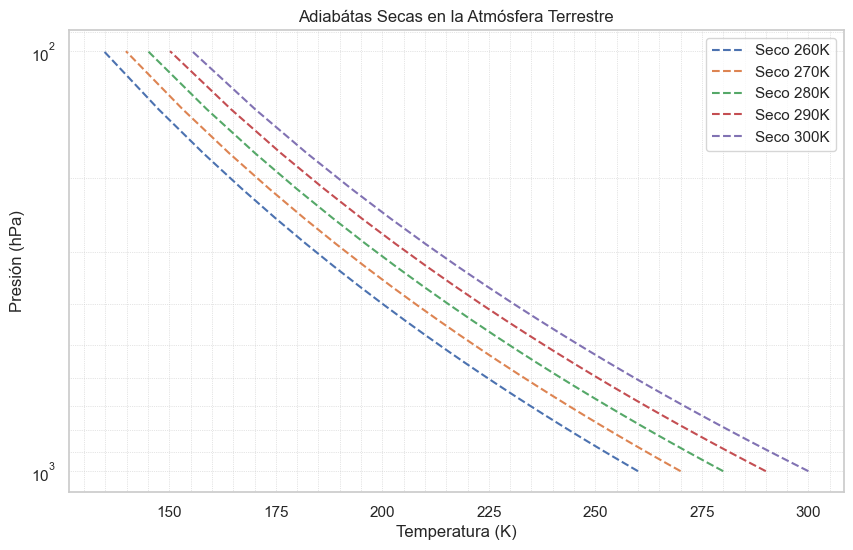

In [14]:
# Pressure levels from 1000 to 100 hPa
P = np.linspace(1000, 100, 25)

# Temperatures for dry adiabats
T0_dry = np.arange(260, 301, 10)  # Starting temperatures from 250K to 300K
dry_adiabats = [calculate_dry_adiabat(T0, P) for T0 in T0_dry]

# Setting up the plot with seaborn styling
sns.set(style="whitegrid")
plt.figure(figsize=(10, 6))

# Plot dry adiabats
for i, T in enumerate(dry_adiabats):
    plt.plot(T, P, label=f'Seco {T0_dry[i]}K', linestyle='--')

plt.gca().invert_yaxis()  # Invert y axis to show pressure decreasing with height
plt.xlabel('Temperatura (K)')
plt.ylabel('Presión (hPa)')
plt.title('Adiabátas Secas en la Atmósfera Terrestre')
# eje logaritmico porque si no, no se ve bonito
plt.gca().set_yscale('log')
plt.legend()
plt.minorticks_on()
plt.grid(True, which='both', linestyle=':', linewidth='0.5')

> **✏️ Ejercicio rápido.** Cada línea es una adiabática seca que arranca de una temperatura distinta en 1000 hPa. Cambia el exponente de Poisson usando `R = 287` por un gas monoatómico (`Cp = 1004` es diatómico; para monoatómico $\kappa=2/5$): ¿las curvas se vuelven más o menos inclinadas? Recuerda que $\kappa=R/C_p$ controla qué tan rápido se enfría la parcela al subir.

<font color="ForestGreen"> Procesos adiabáticos húmedos (saturados) </font>
Cuando el aire contiene vapor de agua y alcanza la saturación, los procesos se vuelven más complejos debido a la liberación de calor latente durante la condensación. En este caso, el gradiente de temperatura es menor que el seco, típicamente entre 4-6°C/km.
Para calcular las adiabáticas húmedas, debemos considerar:

La presión de vapor de saturación usando la aproximación de Bolton:
\begin{align}
e_s(T) = 6.112 \exp\left(\frac{17.67T_c}{243.5 + T_c}\right)
\end{align}

que usamos al principio del notebook. La razón de mezcla de saturación:
\begin{align}
q_s = \frac{M_w}{M_a} \cdot \frac{e_s}{P}
\end{align}

donde $Mw=18.015$ g/mol y $M_a = 28.97$ g/mol son las masas molares del vapor de agua y aire seco, respectivamente.

El gradiente adiabático saturado modificado:
\begin{align}
\Gamma_s = \frac{R_d}{C_p} \cdot \frac{1 + \frac{L q_s}{R_d T}}{1 + \frac{L^2 q_s}{C_p R_v T^2}}
\end{align}

donde:

$L= 2.26 \times 10^6 $ J/kg es el calor latente de vaporización, $R_v = 461.5$ J/(kg·K) es la constante de gas para el vapor de agua.


In [15]:
def saturation_vapor_pressure(T):
    """ Approximate saturation vapor pressure using Clausius-Clapeyron. """
    E0 = 6.11  # hPa, base saturation vapor pressure at T0
    T0 = 273.15  # K, base temperature
    L = 2260e3  # J/kg, latent heat of vaporization
    Rv = 461.5  # J/(kg*K), gas constant for water vapor
    return E0 * np.exp((L/Rv) * (1/T0 - 1/T))

def moist_adiabat(T0, p):
    Rd = 287.0  # J/(kg*K), gas constant for dry air
    Rc = 520.0  # J/(kg*K), gas constant for water vapor
    Cp = 1004   # J/(kg*K), specific heat at constant pressure for air
    L = 2260e3  # J/kg, latent heat of vaporization
    Ma = 28.97  # g/mol, molar mass of dry air
    Mc = 18.015 # g/mol, molar mass of water vapor

    T = np.zeros_like(p)
    T[0] = T0  # Initialize surface temperature in Kelvin

    # Compute temperature profile using the provided lapse rate formula
    for i in range(1, len(p)):
        es = saturation_vapor_pressure(T[i-1])
        q = (Mc / Ma) * (es / p[i-1])
        lapse_rate = (Rd / Cp) * ((1 + (L * q / (Rd * T[i-1]))) / (1 + (L**2 * q / (Cp * Rc * T[i-1]**2))))
        dlnP = np.log(p[i] / p[i-1])
        dlnT = lapse_rate * dlnP
        T[i] = T[i-1] * np.exp(dlnT)

    return T

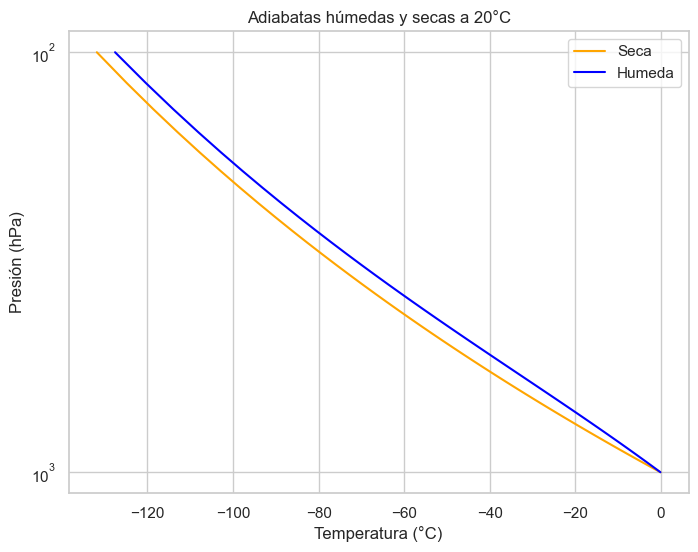

In [16]:
# Pressure levels from 1000 to 100 hPa
p = np.linspace(1000, 100, 50)

# Initial temperature at sea level
T0 = 273  # Celsius

# Calculate adiabats
T_dry = calculate_dry_adiabat(T0, p)
T_moist = moist_adiabat(T0, p)



# Plotting
plt.figure(figsize=(8, 6))
plt.plot(T_dry-273.15, p, label='Seca', color='orange')
plt.plot(T_moist-273.15, p, label='Humeda', color='blue')
plt.gca().invert_yaxis()  # Invert y-axis to align with atmospheric pressure
plt.gca().set_yscale('log')
plt.xlabel('Temperatura (°C)')
plt.ylabel('Presión (hPa)')
plt.minorticks_on()
plt.title('Adiabatas húmedas y secas a 20°C')
plt.legend()
plt.grid(True)


> **✏️ Ejercicio rápido.** La curva húmeda (azul) se enfría más lento que la seca (naranja) porque la condensación libera calor latente. Cambia `T0 = 273` por una superficie más cálida (`T0 = 300`) y compara: ¿la separación entre ambas curvas crece o se reduce? Piensa por qué el aire cálido y húmedo de los trópicos favorece tanto la convección profunda.

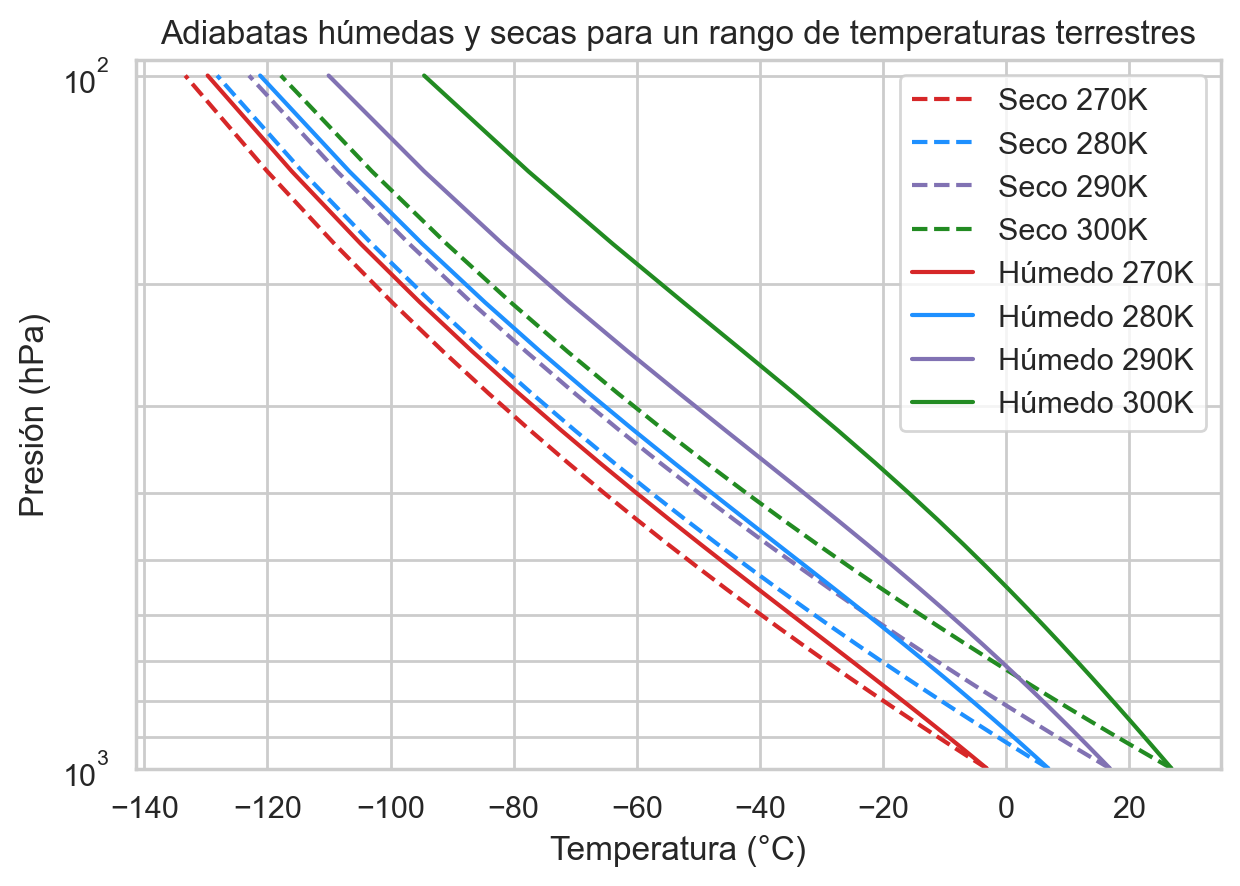

In [17]:
# Pressure levels from 1000 hPa to 100 hPa
p = np.linspace(1000, 100, 50)

# Initial surface temperature
T0 = 285  # Kelvin


# Temperatures for dry adiabats
T0_dry = np.arange(270, 301, 10)  # Starting temperatures from 250K to 300K
dry_adiabats = [calculate_dry_adiabat(T0, P) for T0 in T0_dry]


# Temperatures for moist adiabats
T0_moist = np.arange(270, 301, 10)  

moist_adiabats = [moist_adiabat(T0, P) for T0 in T0_dry]


colors=['tab:red','dodgerblue','m','forestgreen']
plt.figure(figsize=(7, 4.6),dpi=200)

# Plot dry adiabats
for i, T in enumerate(dry_adiabats):
    plt.plot(T-273.15, P, label=f'Seco {T0_dry[i]}K', c=colors[i],linestyle='--',linewidth=1.5)

for i, T in enumerate(moist_adiabats):
    plt.plot(T-273.15, P, label=f'Húmedo {T0_moist[i]}K',c=colors[i])

plt.gca().invert_yaxis()  # Invert y-axis to align with atmospheric pressure
plt.xlabel('Temperatura (°C)')
plt.ylabel('Presión (hPa)')
plt.title('Adiabatas húmedas y secas para un rango de temperaturas terrestres')
plt.gca().set_yscale('log')
plt.yticks(np.arange(100,1001,100))
plt.minorticks_on()
plt.ylim([1000,95])

plt.legend()
plt.grid(True)

---
<a name='ej-3'></a>
### **<font color="DodgerBlue">Ejercicio 3 - Una parcela más realista</font>**

<font color="DarkBlue"> La función `moist_adiabat` que acabamos de usar esconde un supuesto fuerte: recalcula $e_s$ y $q_s$ en cada nivel, lo cual equivale a afirmar que **la parcela ya viene saturada desde la superficie** y se mantiene saturada durante todo el ascenso. Eso casi nunca es cierto. Una parcela real sale de la superficie con una humedad menor que la de saturación, asciende **seca** durante un tramo, y sólo empieza a condensar cuando se ha enfriado lo suficiente.

<font color="DarkBlue"> En este ejercicio vas a construir esa trayectoria realista en dos tramos.

<font color="DarkBlue"> **Instrucciones:**

<font color="DarkBlue"> 1. Parte de una parcela en $1000$ hPa con temperatura $T_0 = 25$ °C y **humedad relativa** del $60\%$. Calcula su presión de vapor inicial $e_0 = \text{HR}\times e_s(T_0)$ y su razón de mezcla $w_0 = 0.622\,e_0/(p_0 - e_0)$.

<font color="DarkBlue"> 2. **Primer tramo (seco).** Haz ascender la parcela por una adiabática seca usando `calculate_dry_adiabat`. Durante este tramo la razón de mezcla $w_0$ **se conserva** (no hay condensación ni mezcla), de modo que la presión de vapor de la parcela en cada nivel es

\begin{align}
e(p) = \frac{w_0\, p}{0.622 + w_0}
\end{align}

<font color="DarkBlue"> 3. **Encuentra el nivel donde comienza la condensación.** Mientras la parcela sube, $e(p)$ disminuye (porque baja la presión) pero $e_s(T)$ disminuye **más rápido** (porque baja la temperatura). En algún nivel se cruzan. Localiza ese nivel: es donde la parcela alcanza la saturación. Reporta la presión y la temperatura a la que ocurre.

<font color="DarkBlue"> 4. **Segundo tramo (húmedo).** A partir de ese nivel, y **sólo a partir de ahí**, continúa el ascenso con la adiabática húmeda. Vas a tener que modificar `moist_adiabat` para que arranque en la presión y temperatura del punto de saturación, en lugar de en la superficie.

<font color="DarkBlue"> 5. Grafica en un diagrama $p$–$T$ la trayectoria completa: el tramo seco, el punto donde cambia de régimen (márcalo claramente), y el tramo húmedo. Como referencia, sobrepón la adiabática seca que habría seguido la parcela si nunca hubiera condensado.

<font color="DarkBlue"> 6. **La parte interesante.** Sigue la trayectoria húmeda hasta arriba, digamos $100$ hPa. Conforme la parcela sube, se va quedando sin vapor: $q_s$ tiende a cero y el calor latente liberado se vuelve despreciable. Calcula la pendiente local $d\ln T/d\ln p$ de tu trayectoria húmeda y compárala con el valor seco $\kappa = R_d/c_p$. ¿A qué presión la trayectoria húmeda se vuelve **paralela** a una adiabática seca otra vez?

<font color="DarkBlue"> 7. Encuentra **cuál** adiabática seca es esa: extrapola tu trayectoria húmeda desde su punto más alto de regreso a $1000$ hPa usando la relación de Poisson seca. La temperatura que obtengas es mayor que la temperatura con la que arrancó la parcela. ¿De dónde salió esa energía extra?

<font color="DarkBlue"> **Sugerencia:** para el paso 3, construye los dos arreglos $e(p)$ y $e_s(T(p))$ sobre la misma malla de presiones y busca el primer índice donde uno supera al otro. `np.where` o `np.argmax` sobre un arreglo booleano te sirven.

<font color="DarkBlue"> **Salida esperada:** una figura con la trayectoria completa en dos tramos y el punto de transición marcado, los valores numéricos de presión y temperatura de saturación, y las respuestas escritas a los puntos 6 y 7.


In [19]:
# Constantes
Rd, Cp_, Rv_, L_ = 287.0, 1004.0, 461.5, 2.5e6
kappa = Rd/Cp_

# Condiciones iniciales de la parcela
p0   = 1000.0   # hPa
T0c  = 25.0     # degC
HR   = 0.60     # humedad relativa

p = np.linspace(1000, 100, 400)   # malla de presiones

# --- 1) Estado inicial: presión de vapor y razón de mezcla -------------
# TU CÓDIGO AQUÍ  (recuerda que bolton() regresa Pa y p está en hPa)
# e0 = ...
# w0 = ...

# --- 2) Tramo seco ----------------------------------------------------
# TU CÓDIGO AQUÍ
# T_seca = calculate_dry_adiabat(...)
# e_parcela = ...            # presión de vapor de la parcela en cada nivel
# es_parcela = ...           # presión de SATURACIÓN a la temperatura de cada nivel

# --- 3) ¿Dónde se cruzan? ---------------------------------------------
# TU CÓDIGO AQUÍ
# idx = ...
# p_sat, T_sat = ...

# --- 4) Tramo húmedo, arrancando en (p_sat, T_sat) --------------------
def moist_adiabat_desde(T_inicial, p_grid):
   # "\"\"Adiabática húmeda que arranca en p_grid[0] con temperatura T_inicial [K].\"\"\"
    # TU CÓDIGO AQUÍ: adapta moist_adiabat para que no asuma que empieza en superficie
    ...

# --- 5) Grafica la trayectoria completa -------------------------------
# TU CÓDIGO AQUÍ

# --- 6 y 7) Pendiente local y adiabática seca equivalente --------------
# TU CÓDIGO AQUÍ


### <font color="DarkSlateBlue"> Resumen </font>

En este notebook recorrimos, de lo general a lo particular, la termodinámica que gobierna al aire atmosférico:

- Empezamos con la **primera ley** y los procesos reversibles (isotermo, adiabata, isocora, isobara), viendo que $\Delta U$ sólo depende de los estados extremos mientras que $Q$ y $W$ dependen del camino.
- Estudiamos la **ecuación de Clausius–Clapeyron** para la presión de saturación del vapor, resolviéndola de tres formas —solución analítica, esquema numérico de diferencias finitas y la aproximación de **Bolton**— y comprobamos que coinciden en el rango de interés.
- Construimos **adiabáticas secas y húmedas** en un diagrama $p$–$T$, y vimos que el aire seco se enfría a ~10 °C/km mientras que el saturado lo hace más lento (4–6 °C/km) por la liberación de calor latente.

Estos diagramas termodinámicos son la herramienta cotidiana de la meteorología operacional: se usan a diario para analizar sondeos atmosféricos y anticipar la estabilidad, la convección y la formación de nubes.

### <font color="Crimson"> Preguntas para reflexionar </font>

- ¿Por qué las montañas "crean" su propio clima? Piensa en lo que le pasa al aire (y a su temperatura) cuando es forzado a subir por una ladera.
- ¿Qué pasaría con la estabilidad atmosférica si no existiera el vapor de agua? ¿Desaparecería la diferencia entre adiabáticas secas y húmedas?
- En una ciudad muy seca como la CDMX durante la temporada seca, ¿esperarías más o menos turbulencia convectiva que en una zona húmeda como Veracruz?
- ¿Por qué los globos aerostáticos se elevan más fácilmente en las mañanas que al mediodía?

### <font color="Crimson"> Ejercicios para cerrar </font>

- Reutiliza `calculate_dry_adiabat` y `moist_adiabat` para calcular el **nivel de condensación** aproximado: el punto donde una parcela seca que asciende alcanza la saturación. Grafica ambas trayectorias juntas y marca dónde se separan.
- Calcula el gradiente adiabático húmedo $\Gamma_s$ como función de la temperatura de superficie y grafícalo: confirma numéricamente que se acerca al seco (~9.8 °C/km) cuando el aire es frío y seco.
- Repite la comparación numérica de Clausius–Clapeyron extendiendo el rango de temperatura a $[-30, 40]$ °C y cuantifica el error máximo de la aproximación de Bolton en ese intervalo.

En el siguiente notebook usaremos estas herramientas para leer sondeos reales y diagnosticar estabilidad e inestabilidad atmosférica.